# Lecture 7. State Estimation 

State Estimation is the broad topic of a robot understanding the current state of itself and its environment, based on sensing and a model of how the robot behaves.  

Typically in robotics we discuss this with respect to mobile robot concepts such as localisation (where is the robot in the world).  

This session applies the statistics methods you learnt from Lecture 6 into the design of a Kalman filter and use it for estimating states of a mobile robot under various noisy sensory conditions.

# Allowed packages 
Do not modify these. Do not add or remove packages.

In [15]:


import numpy as np

import matplotlib.pyplot as plt  # Importing the plotting library

import ipywidgets as widgets
from ipywidgets import interact

from math import sin,cos

from scipy.stats import norm
from scipy.integrate import simpson


---
---
## ✏️ Problem Formulation: State estimation of a robotic car
When a robotic car operates within a complex environment, such as exploring a factory after an earthquake for rescue operations, determining its position can be challenging due to the absence of clear measurements. You are tasked with estimating the car's states by developing a Kalman filter. To simplify this task, initially consider the movement of the robotic car in one degree of freedom, specifically its movement along the horizontal axis as illustrated in Figure 1.

To predict the movement of the car, the following motion transition model is considered, which uses double integration of acceleration to obtain the position of the car:
\begin{align}
x_{k+1} &= Fx_k+\mathbf{v}_k, \quad \mathbf{v}_k\sim \mathcal{N}(0,V) \\
F &= \begin{bmatrix}
1 & \Delta t & \frac{\Delta t^2}{2} \\
0 & 1 & \Delta t \\
0 & 0 & 1
\end{bmatrix}
\end{align}

where the car's state $x_k = (p_k,v_k,a_k)^T$ represents its position, velocity and acceleration at time step $k$, and $\Delta t$ is the time step.

$F$ is the state transition matrix, which describes how the states of the system change between consecutive time steps.

$\mathbf{v}_k$ is the process noise, which represents uncertainty in the state transition model. The process noise is assumed to be normally distributed with a mean of zero and a covariance matrix:

$$V = E[\mathbf{v}_k\mathbf{v}_k^T]$$

This model assumes constant acceleration between consecutive time steps, with deviations from this assumption accounted for by the process noise. Note that $v_k$ is the velocity of the car, whilst $\mathbf{v}_k$ is the process noise vector.

The car has been equipped with GPS such that its position can be observed. However, there is large noise in the measurement in this cluttered environment. The observation model is defined as:
\begin{align}
y_k &= Cx_k + w_k, \quad w_k\sim \mathcal{N}(0,W) \\
C &= \begin{bmatrix}1 & 0 & 0\end{bmatrix}
\end{align}

where $C$ is the observation matrix, which describes the relationship between the states of the system and the variables measured by the sensors.

In this case, the GPS measures the position of the car, but does not directly measure its velocity or acceleration:

$$Cx_k = \begin{bmatrix}1 & 0 & 0\end{bmatrix}\begin{bmatrix}p_k\\v_k\\a_k\end{bmatrix}=p_k$$

$w_k$ is the measurement noise, which is assumed to be normally distributed with a mean of zero and a covariance matrix:

$$W = E[w_kw_k^T]$$

![Robotic car model](rsz_2cart_model-1-1-1.png)

Figure 1. 1-DoF robotic car moving along the horizontal axis, where $p$ is the position of the car relative to the origin $O$.

The Kalman filter is commonly used for motion prediction and for sensor fusion, where multiple measurements of the same state are combined. It was developed independently by several people around the 1960s and used for estimating the movement of rockets. It is generally applied to efficiently combine information from multiple sensors, for example the readings from a GPS sensor together with odometers that measure the movement of the car's wheels, and fuse them together to obtain an estimate of the car's position.

### Assumptions of the Kalman filter

The standard linear Kalman filter, in its Gaussian formulation, makes the following assumptions:

- There is a linear relationship between the states of the system at consecutive time steps (with any known control inputs included in the model).
- There is a linear relationship between the states of the system and the observed variables.
- The process noise and measurement noise are normally distributed with a mean of zero.
- The process noise, measurement noise and initial estimation error are mutually independent. Process and measurement noise are also uncorrelated between time steps.

Note that this does not mean that the position of the car must change linearly with time. For example, the Kalman filter can be used to estimate a sinusoidal trajectory, although the constant-acceleration model used here is only an approximation of that motion.

### Kalman filter matrices

For a system with $n$ states, $m$ measured variables and $r$ known control inputs, the following vectors and matrices are used:

| Symbol | Name | Description | Dimensions |
|---|---|---|---|
| $x_k$ | State vector | The actual states of the system. | $n\times 1$ |
| $\hat{x}_k$ | Estimated state vector | The estimated states after incorporating measurements. | $n\times 1$ |
| $\hat{x}_k^-$ | Predicted state vector | The estimated states before incorporating the latest measurements. | $n\times 1$ |
| $y_k$ | Observation vector | The values measured by the sensors. | $m\times 1$ |
| $\hat{y}_k^-$ | Predicted observation vector | The expected sensor measurements based on the predicted states. | $m\times 1$ |
| $F$ | State transition matrix | Describes how the states change between consecutive time steps. | $n\times n$ |
| $C$ | Observation matrix | Relates the states to the measured variables. | $m\times n$ |
| $G$ | Control input matrix | Describes how the known control inputs affect the states. | $n\times r$ |
| $u_k$ | Control input vector | Contains the known control inputs. | $r\times 1$ |
| $\mathbf{v}_k$ | Process noise vector | Represents uncertainty in the state transition model. | $n\times 1$ |
| $w_k$ | Measurement noise vector | Represents noise in the measurements. | $m\times 1$ |
| $V$ | Process noise covariance matrix | Describes the uncertainty associated with the state transition model. | $n\times n$ |
| $W$ | Measurement noise covariance matrix | Describes the uncertainty associated with the measurements. | $m\times m$ |
| $P_k$ | Estimation error covariance matrix | Describes the uncertainty in the estimated states after incorporating measurements. | $n\times n$ |
| $P_k^-$ | Predicted estimation error covariance matrix | Describes the uncertainty in the predicted states. | $n\times n$ |
| $K_k$ | Kalman gain matrix | Determines how the predicted states are corrected using the measurements. | $n\times m$ |
| $I$ | Identity matrix | Used when updating the estimation error covariance matrix. | $n\times n$ |

In the case of the robotic car with GPS, there are three states (position, velocity and acceleration) and one measured variable (position). Therefore, $n=3$ and $m=1$.

In this session, we do not consider any known control inputs to the system. Therefore, the term $Gu_k$ in the equations below can be omitted.

### Kalman filter algorithm

The principle of the Kalman filter is to find an estimated state $\hat{x}_{k+1}$ that minimises the expected squared estimation error:

$$E[\|x_{k+1}-\hat{x}_{k+1}\|^2]$$

The following iterative equations are used:

![Kalman filter equations](KF_algorithm-1.png)

**Prediction**

The state transition model is used to predict the states of the system at the next time step.

$$\hat{x}_{k+1}^- = F\hat{x}_k + Gu_k$$

The predicted states are used to predict the observations from the sensors.

$$\hat{y}_{k+1}^- = C\hat{x}_{k+1}^-$$

The estimation error covariance matrix is propagated through the state transition model, accounting for the additional uncertainty introduced by the process noise.

$$P_{k+1}^- = FP_kF^T+V$$

**Compute the gain**

The Kalman gain is calculated based on the uncertainty in the predicted states and the uncertainty in the measurements.

$$K_{k+1}=P_{k+1}^-C^T(CP_{k+1}^-C^T+W)^{-1}$$

**Estimation**

The predicted states are corrected using the difference between the actual observations and the predicted observations. This difference is known as the innovation.

$$\hat{x}_{k+1}=\hat{x}_{k+1}^-+K_{k+1}(y_{k+1}-\hat{y}_{k+1}^-)$$

The estimation error covariance matrix is updated to account for the information obtained from the measurements.

$$P_{k+1}=(I-K_{k+1}C)P_{k+1}^-$$

This process is repeated at each time step. The superscript $-$ denotes a prediction, prior to incorporating the measurements at that time step.


---
---
## Task 1.0 - Kalman filter design 

Complete the following code to implement a Kalman filter using the equations defined above.  

In [ ]:
# Code for Task1

def KalmanFilter(F, C, V, W, x0, P0, y):
    '''
    Inputs:
    F - State transition matrix
    C - Observation matrix
    V - Process noise covariance matrix
    W - Observation noise covariance matrix
    x0 - Initial value of state
    P0 - Initial value of error covariance matrix
    y - Noisy observations, a 2D array with MxN dimensions, M represents the modality of the signals, N represents the number of time steps.  
    Output:
    x_hat - Estimated state variable over time
    '''

    # Allocate memory for x_hat based on the number of columns in y
    x_hat = np.zeros((len(x0), y.shape[1]))
      
    # Initialize Kalman filter
    x_hat[:, 0] = x0
    P = P0
  ###########################################################
    # Enter your code here,  
    # Kalman filter loop
    for i in range(y.shape[1] - 1):
        # Prediction
        x_hat_Prior = F @ x_hat[:, i]
        y_hat_Prior = C @ x_hat_Prior
        P = F @ P + F.T + V
    
        # Compute the gain
        K = P @ C.T @ np.linalg.inv(C @ P @ C.T + W)
    
        # Estimation
        x_hat[:, i+1] = x_hat_Prior + K  @ (y[:, i+1] - y_hat_Prior)
        P = (np.eye(F.shape[0]) - K @ C) @ P
    ############################################################
    return x_hat

# End of code for Task 1

---
---
## Task 2.0 - State estimation with GPS measurement 

---
### Task 2.1 

Firstly, let's examine how Kalman filter could use a noisy signal in order to detect a smoother car movement. For simplicity, assume that the robotic car is conducting a repeated scanning task such that it follows a simple sinusoidal wave trajectory $p(t) = 40\sin(t), t\in [0,4\pi]$. The time step $\Delta t = 0.01$ s. 

Complete the following code for simulations of state estimation of the car position using your developed Kalman filter. In this task, the standard deviation of the position noise from GPS $\sigma_w = 1.5$ cm. Plot the true car's trajectory (unknown to the observer), the noisy sensory trajectory from the measurement and estimated trajectory using Kalman filter. 

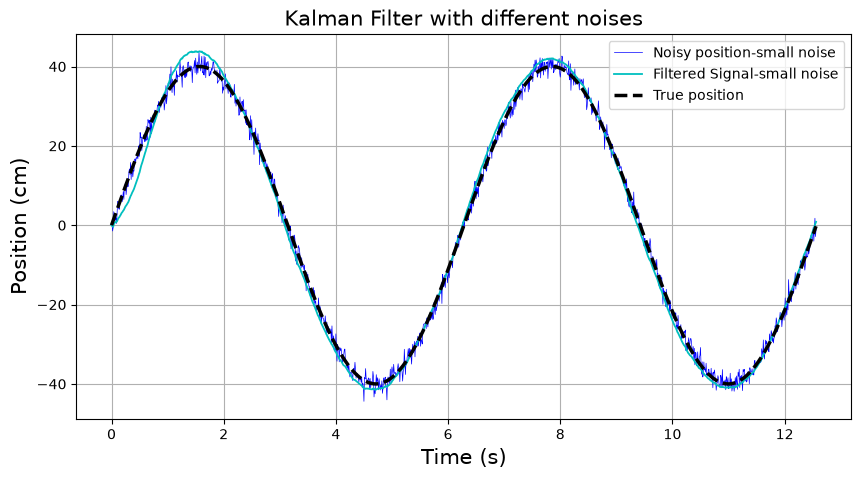

In [ ]:
# Code for Task 2.1
# Discretization of continuous system
dt = 0.01
# Generate time array
t = np.arange(0, 4 * np.pi, dt)

###########################################################
# Enter your code here,  
# Kalman filter matrices
# System transition matrix 
F = np.array([[1,dt,((dt)**2)/2],[0,1,dt],[0,0,1]])
# Observation matrix
C = np.array([1,0,0])

# Measurement noise and variance
Sigma = 1.5
W = Sigma**2 # W is a 1x1 covariance matrix - in this case represented as a scalar
###########################################################

# System noise and covariance matrix
SigmaV = 0.3 
V = np.array([[SigmaV**6 / 36, SigmaV**5 / 12, SigmaV**4 / 6],
              [SigmaV**5 / 12, SigmaV**4 / 4, SigmaV**3 / 2],
              [SigmaV**4 / 6, SigmaV**3 / 2, SigmaV**2]])

# Initialize state
xInit = np.zeros(3)

# Initialize state and error covariance matrices
PInit = np.diag([1, 1, 1])

###########################################################
# Enter your code here, 
# Generate signal and noise corrupted signal
np.random.seed(123456)   # Put in your ID number
x_real = 40 * np.sin(t) # Real sinusoidal trajectory of the movement
y_measurement = x_real + np.random.normal(loc=0, scale=Sigma, size=len(x_real))   # Measured trajectory with noise
y_measurement_2d = np.array([y_measurement])   # convert the measurement into a 2D array

# Run Kalman filter and obtain the estimated trajectory
x_est_0 = KalmanFilter(F,C,V,W,xInit,PInit,y_measurement_2d)
###########################################################

# Plotting
plt.figure(figsize=(10, 5))
plt.plot(t, y_measurement, 'b', linewidth=0.5, label='Noisy position-small noise')
plt.plot(t, x_est_0[0, :], 'c', linewidth=1.3, label='Filtered Signal-small noise')
plt.plot(t, x_real, '--k', linewidth=2.5, label='True position')
plt.legend()
plt.title('Kalman Filter with different noises', fontsize=15)
plt.xlabel('Time (s)', fontsize=15)
plt.ylabel('Position (cm)', fontsize=15)
plt.grid(True)
plt.show()

# End of code for Task 2.1

---
### Task 2.2 

Complete the following function to calculate the mean absolute error (MAE) between the estimated trajectory $\hat{x}_k$ and the real trajectory $x_k$ where $k = 1, 2, \cdots, N$ 
$$MAE = \frac{\sum_{k=1}^{N}(|x_k-\hat{x}_k|)}{N}.$$

Calculate the MAE of the estimated trajectory and compare it with the MAE using the sensory noisy trajectory $y_k$. Describe the difference between the estimated and the measured trajectories.  
 
Hints: to account for the convergence of the Kalman filter, you may consider comparison of trajectories starting from different time steps.

In [ ]:
# Code for Task 2.2
def mae(x_est, x_act):
    """
    Calculate the mean absolute error between estimated trajectory and actual trajectory.
    Args:
    x_est (numpy.array): Estimated values.
    x_act (numpy.array): Actual values.
    Returns:
    float: Computed MAE value.
    """
    ###########################################################
    # Enter your code here, 
    mae = None
    ###########################################################
    return mae

#################################################################################
# Change the initial time instance for calculation of MAE as needed
N_start = 0  # Calculate the estimation error from certain time instance
#################################################################################

error_est = mae(x_est_0[0, N_start:],x_real[N_start:]) # Estimation error   
error_mea = mae(y_measurement[N_start:],x_real[N_start:]) # Measurement error
print("Estimation MAE:", error_est)
print("Measurement MAE:", error_mea)
# End of code for Task 2.2

Ans: 


---
### Task 2.3 

Now assume that the GPS sensor equipped on the robotic car has encountered an issue due to a collision between the car and an unobserved obstacle. The standard deviation of the position measurement noise from GPS increases to $\sigma_w = 4.5$ cm. Repeat the same process in Task 2.1 and Task 2.2. Analyse how this sensory condition affects the estimation accuracy of the Kalman filter.  Complete the following code to conduct the study. 

In [ ]:
# Code for Task 2.3
###########################################################
# Enter your code here, 
# Large measurement noise
Sigma1 = None # Standard deviation of measurement noise
W1 = Sigma1**2 # Variance of measurement noise
y_measurement_noise = None
y_measurement_noise_2d = np.array([y_measurement_noise])   # convert the measurement into a 2D array
# Run Kalman filter and obtain the estimated trajectory
x_est_1 = None
########################################################### 

# Plotting
plt.figure(figsize=(10, 5))
plt.plot(t, y_measurement_noise, 'b', linewidth=0.5, label='Noisy position-large noise')
plt.plot(t, x_est_1[0, :], 'c', linewidth=1.3, label='Filtered Signal-large noise')
plt.plot(t, x_real, '--k', linewidth=2.5, label='True position')
plt.legend()
plt.title('Kalman Filter with large noises', fontsize=15)
plt.xlabel('Time (s)', fontsize=15)
plt.ylabel('Position (cm)', fontsize=15)
plt.grid(True)
plt.show()

#################################################################################
# Change the initial time instance for calculation of MAE as needed
N_start = 0  # Calculate the estimation error from certain time instance
#################################################################################

error_est = mae(x_est_1[0, N_start:],x_real[N_start:]) # Estimation error   
error_mea = mae(y_measurement_noise[N_start:],x_real[N_start:]) # Measurement error
print("Estimation MAE:", error_est)
print("Measurement MAE:", error_mea)

# End of code for Task 2.3

Ans: 

---
### Task 2.4 

The covariance matrix $P_k$ describes the uncertainty associated with the estimated states. Investigate how the convergence of the estimated trajectory depends on the initial covariance matrix $P_0$, by trying
values such as $P_0 = diag(10^5,10^5,10^5)$ and $P_0 = diag(1,1,1)$.

In [ ]:
# Code for Task 2.4
###########################################################
# Enter your code here, 
# Large initial covariance matrix
PInit1 = None
# Run Kalman filter and obtain the estimated trajectory
# Hints: use variance matrix and measured signals with large measurement noise
x_est_2 = None
###########################################################

# Plotting
plt.figure(figsize=(10, 5))
plt.plot(t, y_measurement_noise, 'b', linewidth=0.5, label='Noisy position-large')
plt.plot(t, x_est_2[0, :], 'r', linewidth=1.3, label='Filtered Signal-large noise - Large P0')
plt.plot(t, x_est_1[0, :], 'c', linewidth=1.3, label='Filtered Signal-large noise - Small P0')
plt.plot(t, x_real, '--k', linewidth=2.5, label='True position')
plt.legend()
plt.title('Kalman Filter with large noises', fontsize=15)
plt.xlabel('Time (s)', fontsize=15)
plt.ylabel('Position (cm)', fontsize=15)
plt.grid(True)
plt.show()


#################################################################################
# Change the initial time instance for calculation of MAE as needed
N_start = 0  # Calculate the estimation error from certain time instance
#################################################################################
error_est = mae(x_est_2[0, N_start:], x_real[N_start:]) # Estimation error   
error_mea = mae(y_measurement_noise[N_start:], x_real[N_start:]) # Measurement error
print("Estimation MAE:", error_est)
print("Measurement MAE:", error_mea)

# End of code for Task 2.4

Ans:


---
---
## Task 3.0 - State estimation with sensor fusion from GPS and odometer measurements 
Relying on a single measurement modality for state estimation can be unreliable, particularly in instances of sensor failure. To enhance the reliability of our system design for state estimation, we plan to integrate multiple sensor modalities. This approach will provide diverse sources of information, thereby improving the robustness of the measurements. For example, consider a scenario where the robotic car is equipped with an odometer in addition to its standard GPS. In this case, the measured position of the car would comprise two elements, represented as $y_k = [y_{k,g},\, y_{k,o}]^T$.
\begin{equation} \nonumber
y_k = \begin{bmatrix} 1 & 0 & 0\\ 1 & 0 & 0  \end{bmatrix} x_k + w_k, \quad w_k \sim \mathcal{N}(0, W)
\end{equation}

Suppose that the measurement noise from the GPS and odometer are statistically independent. Therefore, the covariance between the measurement noise of the two sensors is zero, and the measurement noise covariance matrix is:

$$W = \begin{bmatrix}
\sigma_g^2 & 0\\
0 & \sigma_o^2
\end{bmatrix}$$

where $\sigma_g$ and $\sigma_o$ are the standard deviations of the measurement noise from the GPS and odometer respectively.


---
### Task 3.1 

Consider first that the two measurements are subject to the same level of noise with $\sigma_g=\sigma_o=1.5$ cm. To compare the filtering accuracy with only GPS measurement and with both GPS and odometer measurements, plot the estimated states in these two cases, and compare the mean absolute error relative to the ideal movement. 

In [ ]:
# Code for Task 3.1
###########################################################
# Enter your code here, 
# Observation matrix
C2 = None
# Covariance matrix
W2 = None
# Generate noise-corrupted signal
y_2measurement_noise_2d = None
# Run Kalman filter and obtain the estimated trajectory
x_est_3 = None
###########################################################

plt.figure(figsize=(10, 5))
plt.plot(t, y_2measurement_noise_2d[0,:], 'b', linewidth=0.5, label='Noisy position-GPS')
plt.plot(t, y_2measurement_noise_2d[1,:], 'g', linewidth=0.5, label='Noisy position-Odometer')
plt.plot(t, x_est_3[0, :], 'c', linewidth=1.3, label='Filtered Signal')
plt.plot(t, x_real, '--k', linewidth=2.5, label='True position')
plt.legend()
plt.title('Kalman Filter with two sensing modalities', fontsize=15)
plt.xlabel('Time (s)', fontsize=15)
plt.ylabel('Position (cm)', fontsize=15)
plt.grid(True)
plt.show()

#################################################################################
# Change the initial time instance for calculation of MAE as needed
N_start = 0  # Calculate the estimation error from certain time instance
#################################################################################
error_est = mae(x_est_3[0, N_start:],x_real[N_start:]) # Estimation error   
error_mea1 = mae(y_2measurement_noise_2d[0,N_start:],x_real[N_start:]) # Measurement error from GPS
error_mea2 = mae(y_2measurement_noise_2d[1,N_start:],x_real[N_start:]) # Measurement error from Odometer

print("Estimation MAE:", error_est)
print("Measurement MAE of GPS:", error_mea1)
print("Measurement MAE of Odometer:", error_mea2)

# End of code for Task 3.1

Ans: 

---
### Task 3.2 

Suppose that after the collision the standard deviation of the GPS has increased to $\sigma_g=4.5$ cm while the standard deviation of the odometer is not affected i.e. $\sigma_o = 1.5$ cm. Rerun the simulations to investigate how an additional sensing modality could improve the state estimation compared to the single modality. 

In [ ]:
# Code for Task 3.2
###########################################################
# Enter your code here, 
# Covariance matrix
W3 = None  
# Generate noise-corrupted signal
y_2measurement_noise_large_2d = None
# Run Kalman filter and obtain the estimated trajectory
x_est_4 = None
###########################################################

plt.figure(figsize=(10, 5))
plt.plot(t, y_2measurement_noise_large_2d[0,:], 'b', linewidth=0.5, label='Noisy position-GPS')
plt.plot(t, y_2measurement_noise_large_2d[1,:], 'g', linewidth=0.5, label='Noisy position-Odometer')
plt.plot(t, x_est_4[0, :], 'c', linewidth=1.3, label='Filtered Signal')
plt.plot(t, x_real, '--k', linewidth=2.5, label='True position')
plt.legend()
plt.title('Kalman Filter with two sensing modalities and large noises', fontsize=15)
plt.xlabel('Time (s)', fontsize=15)
plt.ylabel('Position (cm)', fontsize=15)
plt.grid(True)
plt.show()

#################################################################################
# Change the initial time instance for calculation of MAE as needed
N_start = 0  # Calculate the estimation error from certain time instance
#################################################################################
error_est = mae(x_est_4[0, N_start:], x_real[N_start:])     # Estimation error   
error_mea1 = mae(y_2measurement_noise_large_2d[0,N_start:],x_real[N_start:]) # Measurement error from GPS
error_mea2 = mae(y_2measurement_noise_large_2d[1,N_start:],x_real[N_start:]) # Measurement error from Odometer

print("Estimation MAE:", error_est)
print("Measurement MAE of GPS:", error_mea1)
print("Measurement MAE of Odometer:", error_mea2)

# End of code for Task 3.2

---
---
## Task 4.0 (Stretch) - The principle of Gaussian Bayes filter

The Kalman filter is a type of Gaussian Bayes filter. The standard Kalman filter assumes Gaussian distributions (including a Gaussian initial state uncertainty) and linear state transition and observation models.

The Bayes filter is a generic framework for state estimation, with many branches and variants. In a Bayes filter, a prior belief is updated using a measurement to form a posterior belief using Bayes' theorem.

In the case of the Kalman filter:

- The prior distribution represents our predicted states and the associated uncertainty.
- The measurement provides additional information about the states of the system.
- The posterior distribution represents our corrected estimated states and the associated uncertainty.

For simplicity, let us consider the estimation of a single state that can be measured directly by a sensor. The prior estimate and the zero-mean measurement noise are Gaussian, with independent errors.

From Lecture 6 we know that the normalised product of the two normal distributions $\mathcal{N}(\mu_1,\sigma_1^2)$ and $\mathcal{N}(\mu_2,\sigma_2^2)$ is another normal distribution $\mathcal{N}(\mu_3,\sigma_3^2)$ with the following properties:
\begin{align*}
\mu_3 &= \dfrac{\mu_2\sigma_1^2+\mu_1\sigma_2^2}{\sigma_1^2+\sigma_2^2}\\
\sigma_3^2 &= \dfrac{\sigma_1^2\sigma_2^2}{\sigma_1^2+\sigma_2^2}
\end{align*}

The equation for the mean of the posterior distribution can also be expressed as:

$$\mu_3=\mu_1+K(\mu_2-\mu_1)$$

where

$$K=\frac{\sigma_1^2}{\sigma_1^2+\sigma_2^2}$$

$K$ is the Kalman gain, $\mu_1$ is the mean of the prior distribution and $\mu_2$ is the observed value. The variances $\sigma_1^2$ and $\sigma_2^2$ represent the uncertainty in the prior estimate and the measurement noise respectively.

The Kalman gain determines how much the prior estimate is corrected based on the observation.


---
### Task 4.1
Consider the following original distributions $\mathcal{N}(\mu_1=5, \sigma_1^{2}=16)$, $\mathcal{N}(\mu_2=2, \sigma_2^{2}=9)$, plot the resultant combined normal distribution with the two original distributions.

In [ ]:
# Code for Task 4.1
###########################################################
# Enter your code here, 
# Define parameters for the two normal distributions
params_1 = {'mu': 5, 'sigma': np.sqrt(16), 'label': 'Normal 1', 'color': 'blue'}
params_2 = {'mu': 2, 'sigma': np.sqrt(9),  'label': 'Normal 2', 'color': 'green'}

# Calculate the joint distribution
mu_joint = None
sigma_joint = None

# Populate parameters dictionary
params_3 = {'mu': mu_joint, 'sigma': sigma_joint, 'label': 'Combined', 'color': 'red'}

# Generate data points for x-axis
x = np.linspace(-10, 15, 1000)

# Calculate the PDF for each normal distribution
pdf_values_1 = None
pdf_values_2 = None
pdf_values_3 = None

###########################################################

# Plot the PDFs for each normal distribution
plt.plot(x, pdf_values_1, label=params_1['label'], color=params_1['color'])
plt.plot(x, pdf_values_2, label=params_2['label'], color=params_2['color'])
plt.plot(x, pdf_values_3, label=params_3['label'], color=params_3['color'])

# Add labels and title
plt.xlabel('X-axis')
plt.ylabel('Probability Density')
plt.title('Three Normal Distributions')
plt.legend()

# End of code for Task 4.1


### Task 4.2
Have a play with the interactive example below and consider the following conditions:
1. What is the variance of posterior estimated values if the variances of prior estimated values and observations are the same with arbitrary means?

Ans: 

2. Assume the observation is very accurate, and is far from the prior estimate with large variance. What happens to the mean and variance of the posterior estimated values?

Ans: 

3. What about the opposite case, many repeat readings had led to a prior estimate with high confidence (small variance), if a new observation comes in far outside this region, how accurate does the new observation need to be to get the estimate to budge?

Ans: 

In [ ]:
# Task 4.2 
# You don't need to change any code for the interaction
# Normal distributions of the same variable can be combined by simple multiplication

def plot_combined_normal_distributions(mean1, variance1, mean2, variance2):
    # Generate values for the x-axis
    x = np.linspace(-5, 5, 1000)

    # Create the two normal distribution PDFs
    distribution1 = norm.pdf(x, loc=mean1, scale=np.sqrt(variance1))
    distribution2 = norm.pdf(x, loc=mean2, scale=np.sqrt(variance2))

    # Calculate the addition of the two distributions
    combined_distribution = distribution1 * distribution2

    # Normalize the combined distribution
    normalised_combined_distribution = combined_distribution / simpson(combined_distribution, x)

    # Create the plot
    plt.figure(figsize=(10, 5))
    plt.plot(x, distribution1, label=f'Prior Estimate: μ={mean1:.2f}, σ²={variance1:.2f}')
    plt.plot(x, distribution2, label=f'Observation: μ={mean2:.2f}, σ²={variance2:.2f}')
    plt.plot(x, normalised_combined_distribution, label='Combined Distribution (Normalized)', linestyle='--')

    # Set plot labels and custom legend
    plt.xlabel('X')
    plt.ylabel('Probability Density')
    plt.title('Combined Normal Distributions (Normalized)')
    
    legend = plt.legend()
    for label in legend.get_texts():
        label.set_text(label.get_text().replace('μ', 'mean').replace('σ²', 'variance'))
    
    # Show the plot
    plt.grid(True)
    plt.show()

# Create sliders for mean and variance of the two distributions
mean_slider1 = widgets.FloatSlider(value=0, min=-5, max=5, step=0.1, description='Mean 1')
variance_slider1 = widgets.FloatSlider(value=1, min=0.1, max=5, step=0.1, description='Variance 1')
mean_slider2 = widgets.FloatSlider(value=1, min=-5, max=5, step=0.1, description='Mean 2')
variance_slider2 = widgets.FloatSlider(value=1, min=0.1, max=5, step=0.1, description='Variance 2')

# Create an interactive plot using the 'interact' function
interact(plot_combined_normal_distributions, mean1=mean_slider1, variance1=variance_slider1, mean2=mean_slider2, variance2=variance_slider2)

interactive(children=(FloatSlider(value=0.0, description='Mean 1', max=5.0, min=-5.0), FloatSlider(value=1.0, …

<function __main__.plot_combined_normal_distributions(mean1, variance1, mean2, variance2)>

## References

[1] Tutorial of linear quadratic estimation (LQE), Human neuromechemical control and learning, Imperial College London.  

